--- ESTOS SON LOS PESOS SECRETOS DE LA FÓRMULA ---
                    Campo      Peso
3             Alcohol_Use  0.103744
10          Air_Pollution  0.099443
7   Diet_Salted_Processed  0.098092
2                 Smoking  0.090997
11   Occupational_Hazards  0.087371
6           Diet_Red_Meat  0.084303
4                 Obesity  0.078490
0                     Age  0.067001
15                    BMI  0.066737
8        Fruit_Veg_Intake  0.048964


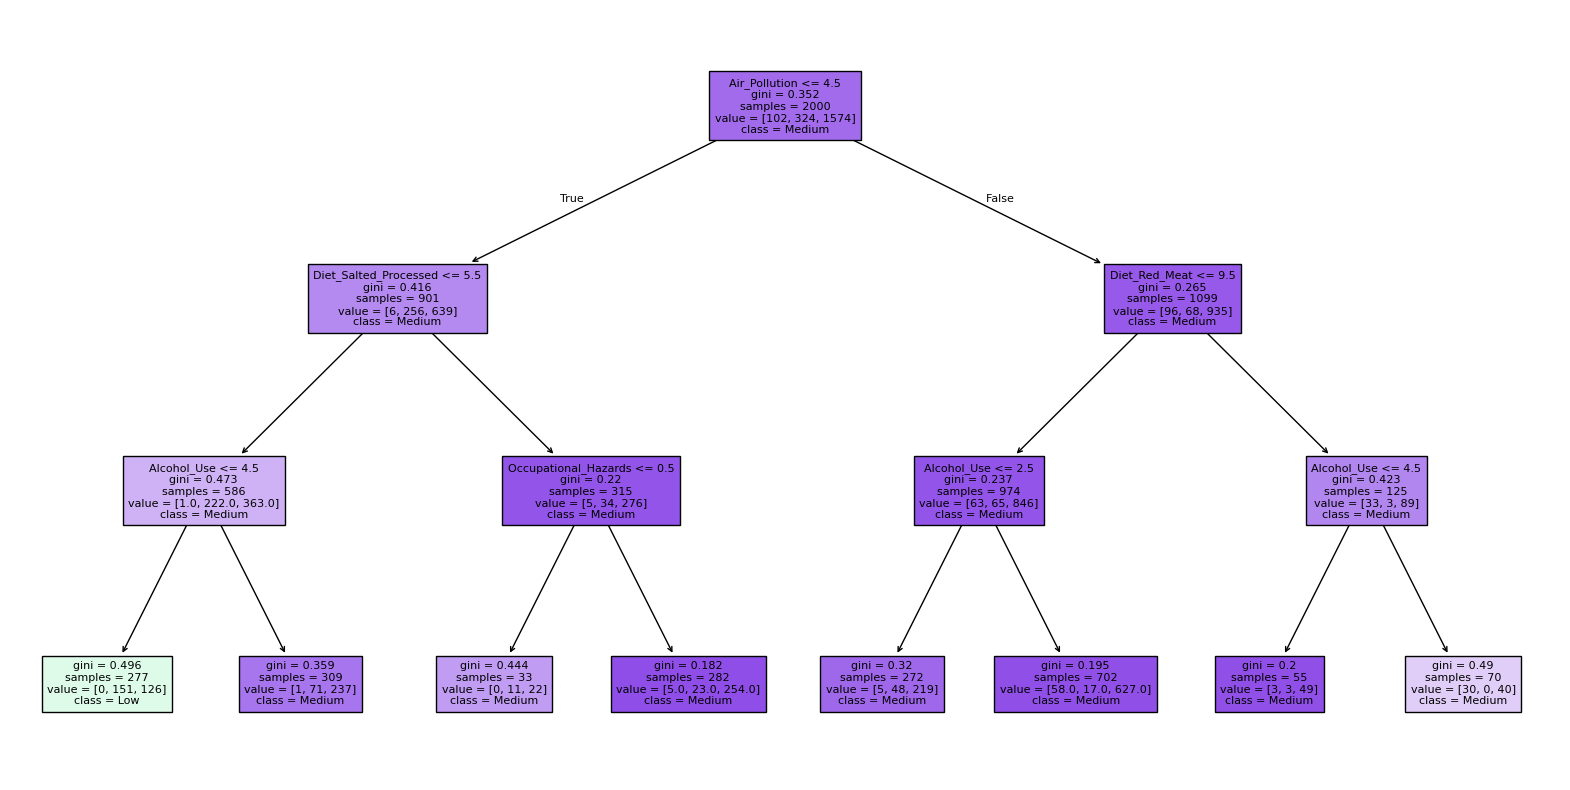

In [7]:
#------------------------------------------------------------------------------------------------------------------------
# Proposito: la iformacion etiquetada el calculo de riesgo peso ya esta registrado, por tal razon si bien no hace parte
#            del analisis, si se considera que es importante saber esos valores como fueron calculado para saber el 
#            origen de sus valores
#-------------------------------------------------------------------------------------------------------------------------

import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

# 1. AHORA SÍ, AQUÍ ESTÁ SU ARCHIVO, PARCE
df = pd.read_csv('cancer-risk-factors.csv')

# 2. Limpiamos lo que NO debe ser pista
# Quitamos la etiqueta y el Score tramposo
X = df.drop(columns=['Patient_ID','Risk_Level','Overall_Risk_Score','Cancer_Type'], errors='ignore')
X = pd.get_dummies(X, drop_first=True) # pa' convertir los Si/No en 1/0
y = df['Risk_Level'] # Aquí le digo dónde está la etiqueta reina

# 3. El soplón rápido: ¿Qué pesa más?
modelo = RandomForestClassifier(random_state=42).fit(X, y)

importancias = pd.DataFrame({
    'Campo': X.columns,
    'Peso': modelo.feature_importances_
}).sort_values('Peso', ascending=False)

print("--- ESTOS SON LOS PESOS SECRETOS DE LA FÓRMULA ---")
print(importancias.head(10))

# 4. La confesión: El arbolito que muestra la fórmula
arbolito = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X, y)

plt.figure(figsize=(20,10))
plot_tree(arbolito, feature_names=X.columns, class_names=arbolito.classes_, filled=True, fontsize=8)

plt.savefig("arbol_decision.png", dpi=200, bbox_inches='tight')

plt.show()
